# Task 4 — Email Spam Detection with Machine Learning

## Project Overview
This notebook builds an end-to-end NLP binary classifier for **spam vs ham** messages using the UCI SMS Spam Collection supplied as `spam.csv`.


### Workflow
**Dataset → Inspection → Cleaning → Class Distribution → Text Preprocessing → TF-IDF → Train/Test Split → Multinomial Naive Bayes + Logistic Regression → Evaluation → Confusion Matrices → Language Analysis → WordCloud → Demonstration Predictions → Error Analysis → Findings → Limitations → Checklist**

## Objective

The goal is to distinguish:
- **Spam:** unwanted/promotional or otherwise spam-labelled messages.
- **Ham:** legitimate/non-spam messages.

This is a **binary classification** problem because each message belongs to one of two target classes. NLP is useful because the message text contains linguistic patterns and terms that can be converted into numerical features for machine-learning algorithms.

Two classical classifiers are compared:
1. **Multinomial Naive Bayes**
2. **Logistic Regression**

## Dataset Source

The dataset is the **SMS Spam Collection**, hosted by the **UCI Machine Learning Repository**. UCI describes it as a public collection of labelled SMS messages for mobile-phone spam research and reports **5,574 instances** in the original collection.

**Original source:** UCI Machine Learning Repository  
**URL:** https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset

The supplied `spam.csv` is a CSV-formatted copy of this collection. The supplied file contains 5,572 rows and a label/message structure (`v1`/`v2`) plus three mostly empty unnamed columns. Those extra columns are handled explicitly because some messages contain commas that were split across columns during CSV formatting.

**Important limitation:** UCI's collection contains **SMS messages**, not email bodies. The workflow is transferable to email spam classification, but performance on real email data should not be assumed from this experiment alone.

In [1]:
# Core libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

sns.set_style("whitegrid")

RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_PATH = "spam.csv"

## Load Dataset

The file is loaded with `latin1` encoding because the supplied CSV contains byte sequences that are not valid UTF-8. We first inspect the raw schema rather than assuming that it is already clean.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="latin1")

print("Shape:", df_raw.shape)
print("\nColumns:", df_raw.columns.tolist())
print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nFirst five rows:")
display(df_raw.head())

Shape: (5572, 5)

Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Data types:


,dtype
v1,object
v2,object
Unnamed: 2,object
Unnamed: 3,object
Unnamed: 4,object



First five rows:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Initial Data Inspection

The expected information is a message label and a message text. The supplied CSV also contains `Unnamed: 2`, `Unnamed: 3`, and `Unnamed: 4`. These columns are mostly empty, but some non-null cells contain message fragments that were separated by commas. Therefore, simply dropping those columns would lose text.

We reconstruct each message by joining `v2` and any non-null unnamed fragments with commas, then retain only the label and reconstructed message.

In [3]:
print("Missing values in raw file:")
display(df_raw.isnull().sum().to_frame("missing"))

print("Exact duplicate raw rows:", df_raw.duplicated().sum())

print("\nLabel counts:")
display(df_raw["v1"].value_counts(dropna=False).to_frame("count"))

print("\nNon-null counts in unnamed columns:")
for col in [c for c in df_raw.columns if c.startswith("Unnamed:")]:
    print(f"{col}: {df_raw[col].notna().sum()}")

Missing values in raw file:


,missing
v1,0
v2,0
Unnamed: 2,5522
Unnamed: 3,5560
Unnamed: 4,5566


Exact duplicate raw rows: 403

Label counts:


,count
v1,
ham,4825
spam,747



Non-null counts in unnamed columns:
Unnamed: 2: 50
Unnamed: 3: 12
Unnamed: 4: 6


In [4]:
# Reconstruct messages from the message column plus any comma-split fragments.
unnamed_cols = [c for c in df_raw.columns if c.startswith("Unnamed:")]

def reconstruct_message(row):
    parts = [str(row["v2"])]
    for col in unnamed_cols:
        if pd.notna(row[col]):
            parts.append(str(row[col]))
    return ",".join(parts)

df = pd.DataFrame({
    "label": df_raw["v1"].astype(str).str.strip().str.lower(),
    "message": df_raw.apply(reconstruct_message, axis=1)
})

print("Reconstructed dataset shape:", df.shape)
display(df.head())

Reconstructed dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Data Quality Checks

We check for:
- missing values,
- empty messages,
- unexpected labels,
- non-string messages,
- duplicate message/label pairs,
- duplicate message text with conflicting labels,
- message-length extremes.

Exact duplicate records are removed **before** the train/test split to reduce the risk of the same repeated message appearing in both partitions. No message text has conflicting labels in this supplied dataset.

In [5]:
quality = {
    "missing_labels": int(df["label"].isna().sum()),
    "missing_messages": int(df["message"].isna().sum()),
    "empty_messages": int((df["message"].str.strip() == "").sum()),
    "non_string_messages": int((~df["message"].map(lambda x: isinstance(x, str))).sum()),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "unique_labels": df["label"].nunique(),
}
display(pd.Series(quality, name="value").to_frame())

print("Unique labels:", sorted(df["label"].unique().tolist()))

conflicting = (
    df.groupby("message")["label"].nunique().gt(1).sum()
)
print("Messages appearing with conflicting labels:", int(conflicting))

length_stats = df["message"].str.len().describe()
display(length_stats.to_frame("message_length"))

,value
missing_labels,0
missing_messages,0
empty_messages,0
non_string_messages,0
exact_duplicate_rows,403
unique_labels,2


Unique labels: ['ham', 'spam']
Messages appearing with conflicting labels: 0


,message_length
count,5572.000000
mean,80.692211
std,60.007878
min,2.000000
25%,36.000000
50%,62.000000
75%,123.000000
max,910.000000


In [6]:
# Remove exact duplicate label/message records before splitting.
before = len(df)
df = df.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)
removed_duplicates = before - len(df)

# Remove only rows that are actually unusable.
before_empty = len(df)
df = df[df["message"].str.strip().ne("")].reset_index(drop=True)
removed_empty = before_empty - len(df)

print(f"Duplicate rows removed: {removed_duplicates}")
print(f"Empty-message rows removed: {removed_empty}")
print(f"Final modelling rows: {len(df)}")

display(df["label"].value_counts().to_frame("count"))

Duplicate rows removed: 403
Empty-message rows removed: 0
Final modelling rows: 5169


,count
label,
ham,4516
spam,653


## Class Distribution

Spam detection datasets are often imbalanced because legitimate messages can outnumber spam messages. We calculate both counts and percentages and visualize the result.

**Observation:** The interpretation below is generated from the actual cleaned dataset rather than assumed in advance.

,count,percentage
label,,
ham,4516,87.37
spam,653,12.63


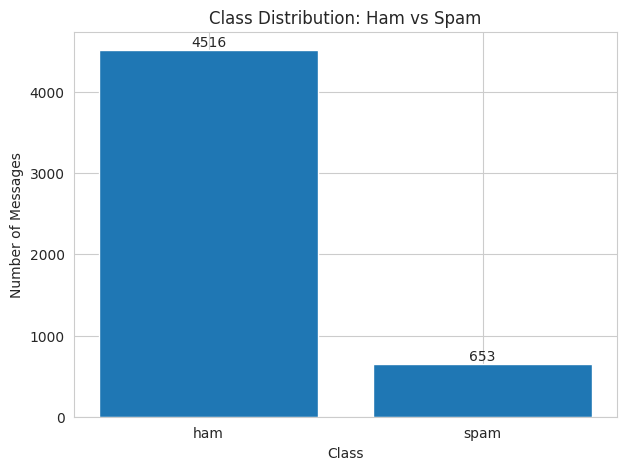

Observation: The cleaned dataset is imbalanced: spam represents 12.63% of messages, while ham is the majority class. Accuracy alone can therefore hide differences in spam detection performance.


In [7]:
class_counts = df["label"].value_counts().reindex(["ham", "spam"])
class_percent = (class_counts / class_counts.sum() * 100).round(2)

class_distribution = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percent
})
display(class_distribution)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(class_distribution.index, class_distribution["count"])
ax.set_title("Class Distribution: Ham vs Spam")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Messages")

for bar, value in zip(bars, class_distribution["count"]):
    ax.text(bar.get_x() + bar.get_width()/2,
            value + class_distribution["count"].max() * 0.01,
            str(value), ha="center")

plt.show()

minority_pct = class_percent["spam"]
if minority_pct < 40:
    observation = (
        f"The cleaned dataset is imbalanced: spam represents {minority_pct:.2f}% "
        "of messages, while ham is the majority class. Accuracy alone can therefore "
        "hide differences in spam detection performance."
    )
else:
    observation = (
        f"Spam represents {minority_pct:.2f}% of messages. The class distribution is "
        "not extremely skewed, but precision, recall and F1-score are still useful."
    )
print("Observation:", observation)

## Text Preprocessing

A reusable preprocessing function performs:
1. lowercase conversion,
2. punctuation and special-character removal,
3. whitespace normalization,
4. stopword removal.

We use Python `re` plus scikit-learn's built-in English stopword list, so no external NLTK corpus download is required.

### Why no stemming/lemmatization?
For this short-message dataset, a simpler pipeline is easier to reproduce and avoids introducing another linguistic transformation that is not necessary for the assignment. The effect of stemming/lemmatization would need to be tested experimentally before claiming that it improves performance.

### NLP trade-off
Removing punctuation and special characters can also remove useful spam signals such as repeated punctuation, currency symbols, URLs, and unusual formatting. This is a deliberate baseline preprocessing choice rather than a claim that removing these signals is always optimal.

In [8]:
STOPWORDS = set(ENGLISH_STOP_WORDS)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    tokens = [token for token in text.split() if token not in STOPWORDS]
    return " ".join(tokens)

df["clean_text"] = df["message"].apply(preprocess_text)

comparison = df[["message", "clean_text"]].head(8).copy()
display(comparison)

,message,clean_text
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis n great wor...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun say early hor u c say
4,"Nah I don't think he goes to usf, he lives aro...",nah don t think goes usf lives
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling s 3 week s word d like fun...
6,Even my brother is not like to speak with me. ...,brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,request melle melle oru minnaminunginte nurung...


## Original vs Cleaned Text — Observation

The examples above show how casing, punctuation/special characters, and common English stopwords are reduced before vectorization. Some tokens that may carry spam-specific information (for example numbers) are retained because the regular expression keeps alphanumeric characters.

## What is TF-IDF?

**TF-IDF = Term Frequency × Inverse Document Frequency**

- **TF (Term Frequency):** measures how often a term occurs in a document.
- **IDF (Inverse Document Frequency):** reduces the importance of terms that appear in many documents.
- Their product gives a weight that emphasizes terms that are relatively informative for individual documents.

A smoothed form consistent with scikit-learn's `TfidfVectorizer` is:

`IDF(t) = log((N + 1) / (df(t) + 1)) + 1`

where `N` is the number of training documents and `df(t)` is the number of training documents containing term `t`.

TF-IDF is useful here because messages can be represented as sparse numerical vectors while terms that are common everywhere receive less distinguishing weight.

## Train/Test Split

The cleaned text and labels are split into training and testing sets. The test set is kept unseen while the models learn.

`stratify=y` preserves approximately the same spam/ham class proportions in both partitions, which is useful when the classes are imbalanced.

In [9]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame("percentage"))
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame("percentage"))

Training rows: 4135
Testing rows: 1034

Training class proportions:


,percentage
label,
ham,87.38
spam,12.62



Testing class proportions:


,percentage
label,
ham,87.33
spam,12.67


## TF-IDF Feature Extraction and Data Leakage Prevention

The vectorizer must be **fit only on training data**. If it were fit on the entire dataset before the split, information about the test corpus would influence feature construction.

To make this safe and reproducible, each classifier is placed in a scikit-learn `Pipeline`. The TF-IDF vectorizer is therefore fitted inside the training process and only transforms the unseen test messages afterward.

The baseline vectorizer uses:
- `stop_words=None` because stopwords were already removed by our preprocessing function,
- `ngram_range=(1, 2)` to include unigrams and bigrams,
- `min_df=2` to ignore terms appearing in only one training document,
- `max_df=0.95` to ignore terms appearing in almost all training documents.

In [10]:
tfidf_params = dict(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    lowercase=False
)

nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_params)),
    ("classifier", MultinomialNB())
])

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_params)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

nb_pipeline.fit(X_train, y_train)
lr_pipeline.fit(X_train, y_train)

nb_features = nb_pipeline.named_steps["tfidf"].get_feature_names_out()
lr_features = lr_pipeline.named_steps["tfidf"].get_feature_names_out()

print("Naive Bayes TF-IDF feature count:", len(nb_features))
print("Logistic Regression TF-IDF feature count:", len(lr_features))
print("Expected feature matrix shape for NB:", (len(X_train), len(nb_features)))

Naive Bayes TF-IDF feature count: 5628
Logistic Regression TF-IDF feature count: 5628
Expected feature matrix shape for NB: (4135, 5628)


## Model 1 — Multinomial Naive Bayes

Multinomial Naive Bayes is a common baseline for text classification because it works naturally with non-negative word-feature representations and is computationally efficient for sparse text data.

The model below is trained through the TF-IDF pipeline.

In [11]:
nb_predictions = nb_pipeline.predict(X_test)

print("Multinomial Naive Bayes classification report:")
print(classification_report(y_test, nb_predictions, labels=["ham", "spam"], digits=4))

Multinomial Naive Bayes classification report:
              precision    recall  f1-score   support

         ham     0.9658    1.0000    0.9826       903
        spam     1.0000    0.7557    0.8609       131

    accuracy                         0.9691      1034
   macro avg     0.9829    0.8779    0.9217      1034
weighted avg     0.9701    0.9691    0.9672      1034



## Model 2 — Logistic Regression

Logistic Regression is a second classical classifier that is well suited to high-dimensional sparse TF-IDF representations. It provides a useful comparison with Naive Bayes without requiring a substantially different feature representation.

In [12]:
lr_predictions = lr_pipeline.predict(X_test)

print("Logistic Regression classification report:")
print(classification_report(y_test, lr_predictions, labels=["ham", "spam"], digits=4))

Logistic Regression classification report:
              precision    recall  f1-score   support

         ham     0.9545    0.9989    0.9762       903
        spam     0.9888    0.6718    0.8000       131

    accuracy                         0.9574      1034
   macro avg     0.9716    0.8353    0.8881      1034
weighted avg     0.9588    0.9574    0.9539      1034



## Evaluation Metrics

For this project, **spam is the positive class**.

- **Accuracy:** proportion of all test messages classified correctly.
- **Precision:** among messages predicted as spam, the proportion that are actually spam.
- **Recall:** among actual spam messages, the proportion detected as spam.
- **F1-score:** harmonic mean of precision and recall.

Recall is particularly relevant because a false negative means an actual spam message was classified as ham. However, precision also matters because false positives can cause legitimate messages to be incorrectly filtered.

In [13]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label="spam"),
        "Recall": recall_score(y_true, y_pred, pos_label="spam"),
        "F1-Score": f1_score(y_true, y_pred, pos_label="spam"),
    }

results = pd.DataFrame([
    evaluate_model("Multinomial Naive Bayes", y_test, nb_predictions),
    evaluate_model("Logistic Regression", y_test, lr_predictions),
])

display(results.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}",
}))

,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.9691,1.0000,0.7557,0.8609
1,Logistic Regression,0.9574,0.9888,0.6718,0.8000


## Why is Recall Important for Spam Detection?

A **false negative** occurs when a real spam message is classified as ham. In a spam filter, this means unwanted or potentially harmful content can reach the user's normal inbox.

Increasing spam recall can reduce these missed spam messages, but it can also increase false positives. A false positive occurs when a legitimate message is classified as spam, which can be inconvenient or harmful if the user misses an important message.

Therefore, spam detection should consider **recall, precision, and F1-score together**, rather than treating accuracy as the only objective.

## Confusion Matrices

The confusion matrices show:
- **True Negative (TN):** ham predicted as ham
- **False Positive (FP):** ham predicted as spam
- **False Negative (FN):** spam predicted as ham
- **True Positive (TP):** spam predicted as spam

The false-negative cell is especially important when examining how much actual spam each model misses.

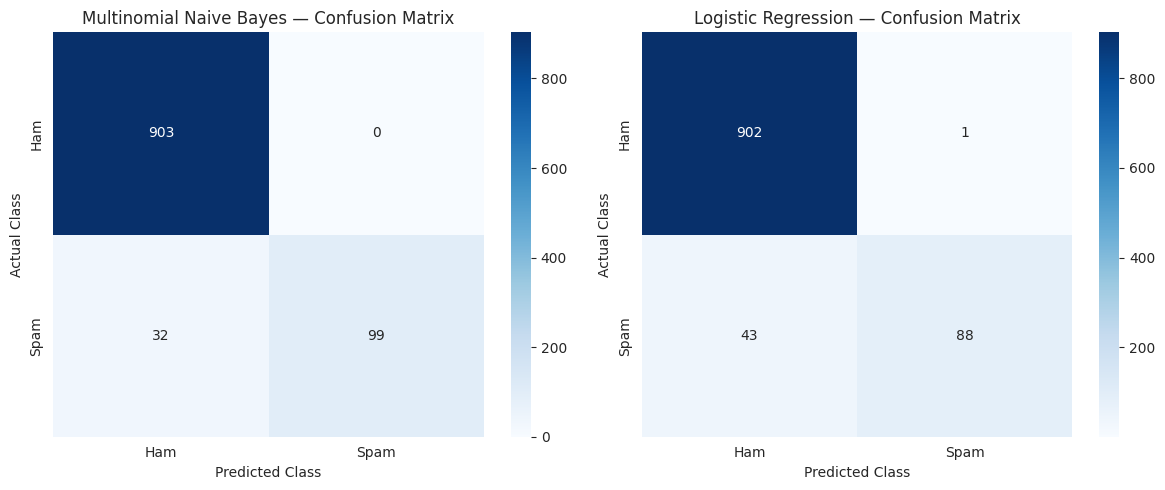

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, title, predictions in [
    (axes[0], "Multinomial Naive Bayes", nb_predictions),
    (axes[1], "Logistic Regression", lr_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=["ham", "spam"])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )
    ax.set_title(f"{title} — Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

## Model Comparison

The following chart compares the actual test-set metrics. The purpose is to describe trade-offs rather than declare a universal winner.

When interpreting the chart, pay particular attention to:
- spam recall,
- spam precision,
- F1-score,
- overall accuracy.

A model with higher recall but lower precision would detect more spam while also risking more legitimate messages being marked as spam.

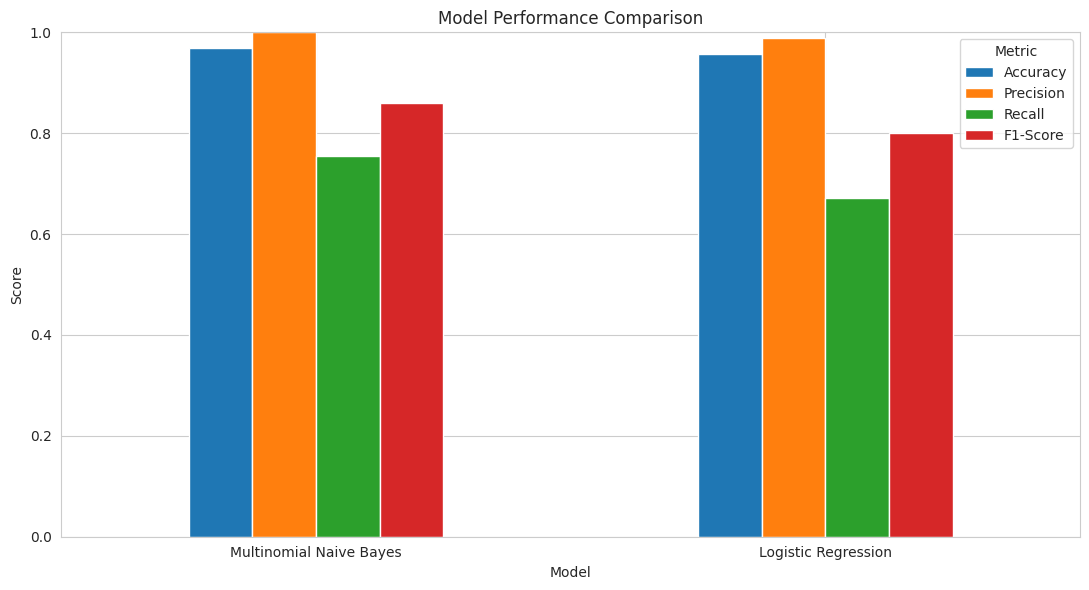

Accuracy: Multinomial Naive Bayes = 0.9691; other model = 0.9574
Precision: Multinomial Naive Bayes = 1.0000; other model = 0.9888
Recall: Multinomial Naive Bayes = 0.7557; other model = 0.6718
F1-Score: Multinomial Naive Bayes = 0.8609; other model = 0.8000


In [15]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
plot_df = results.set_index("Model")[metrics]

ax = plot_df.plot(kind="bar", figsize=(11, 6))
ax.set_title("Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

# Dynamic objective-oriented comparison statements.
for metric in metrics:
    vals = results.set_index("Model")[metric]
    higher = vals.idxmax()
    print(f"{metric}: {higher} = {vals.max():.4f}; other model = {vals.min():.4f}")

## Spam vs Ham Language Analysis

A frequency analysis provides an interpretable view of recurring terms in the two classes. This is descriptive: a frequently occurring word does **not** prove that an individual message is spam.

We use the cleaned text and count individual tokens separately for spam and ham.

Top spam-associated tokens by frequency:


,word,count
0,free,195
1,2,185
2,u,147
3,txt,134
4,ur,119
5,4,114
6,stop,111
7,mobile,109
8,text,108
9,claim,96


Top ham-associated tokens by frequency:


,word,count
0,u,930
1,s,479
2,m,395
3,t,384
4,2,306
5,gt,288
6,lt,287
7,just,282
8,ok,256
9,ll,233


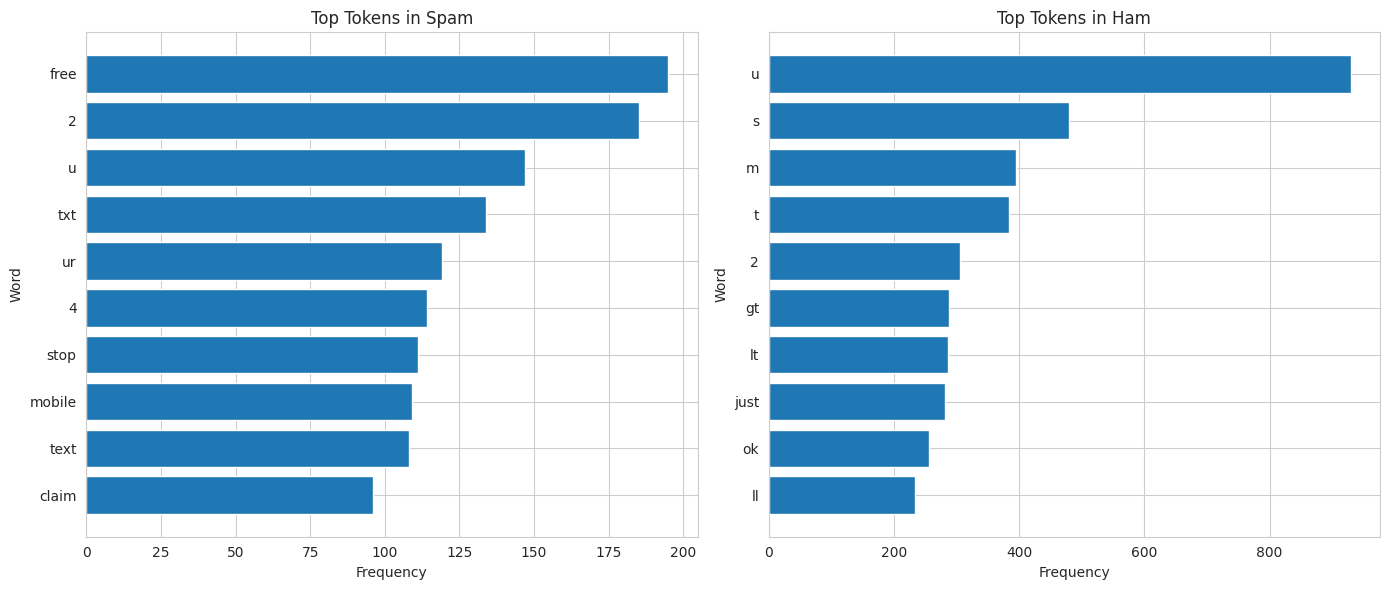

In [16]:
from collections import Counter

spam_tokens = " ".join(df.loc[df["label"] == "spam", "clean_text"]).split()
ham_tokens = " ".join(df.loc[df["label"] == "ham", "clean_text"]).split()

spam_freq = pd.DataFrame(Counter(spam_tokens).most_common(15), columns=["word", "count"])
ham_freq = pd.DataFrame(Counter(ham_tokens).most_common(15), columns=["word", "count"])

print("Top spam-associated tokens by frequency:")
display(spam_freq)

print("Top ham-associated tokens by frequency:")
display(ham_freq)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

spam_top = spam_freq.head(10).sort_values("count")
axes[0].barh(spam_top["word"], spam_top["count"])
axes[0].set_title("Top Tokens in Spam")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Word")

ham_top = ham_freq.head(10).sort_values("count")
axes[1].barh(ham_top["word"], ham_top["count"])
axes[1].set_title("Top Tokens in Ham")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Word")

plt.tight_layout()
plt.show()

## Bonus — WordCloud Analysis

WordCloud is optional. If the package is unavailable, the frequency plots above still provide a valid alternative and the notebook continues to run.

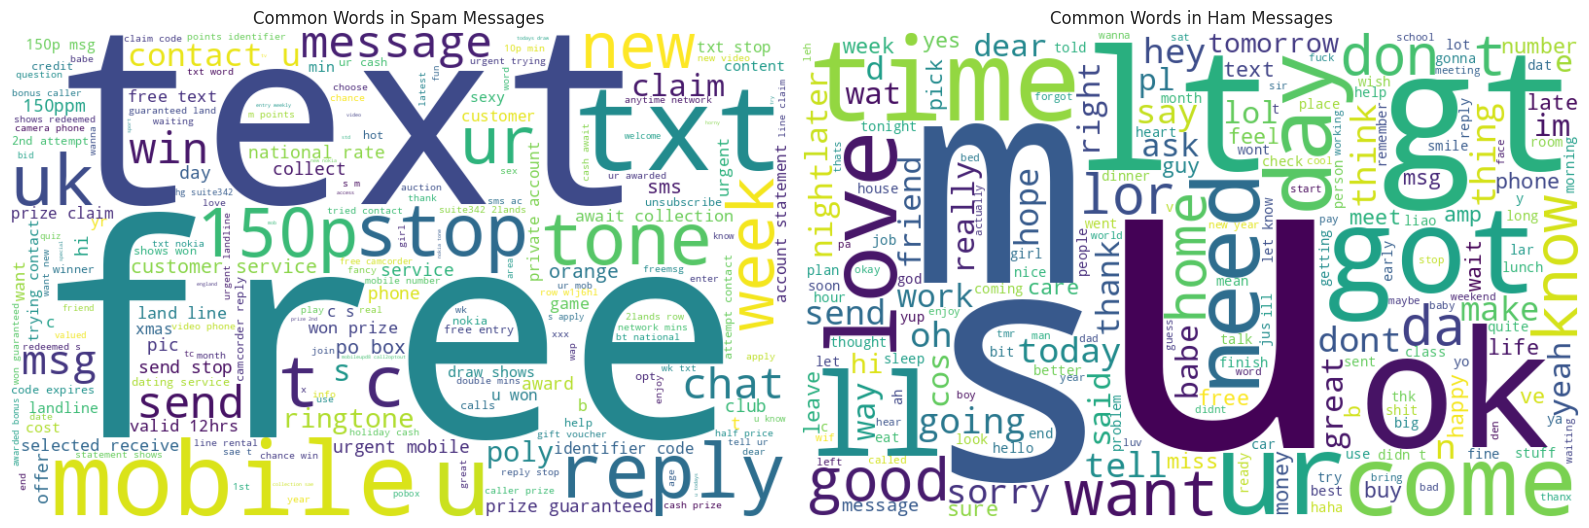

WordCloud bonus: PASS


In [17]:
try:
    from wordcloud import WordCloud

    spam_text = " ".join(df.loc[df["label"] == "spam", "clean_text"])
    ham_text = " ".join(df.loc[df["label"] == "ham", "clean_text"])

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    spam_wc = WordCloud(width=800, height=500, background_color="white").generate(spam_text)
    axes[0].imshow(spam_wc, interpolation="bilinear")
    axes[0].axis("off")
    axes[0].set_title("Common Words in Spam Messages")

    ham_wc = WordCloud(width=800, height=500, background_color="white").generate(ham_text)
    axes[1].imshow(ham_wc, interpolation="bilinear")
    axes[1].axis("off")
    axes[1].set_title("Common Words in Ham Messages")

    plt.tight_layout()
    plt.show()
    print("WordCloud bonus: PASS")
except ImportError:
    print("WordCloud is not installed. Frequency-based word analysis above is the fallback.")

## Prediction Demonstration

The examples below are **demonstration inputs**, not validation data. They are passed through the same trained pipeline used for the test messages.

In [18]:
demo_messages = [
    "Hi, are we still meeting for lunch today?",
    "Congratulations! You have won a free cash prize. Call now to claim your reward.",
    "Can you send me the notes from today's class?",
    "URGENT! Claim your exclusive reward now by texting WIN to 80000."
]

demo_clean = [preprocess_text(msg) for msg in demo_messages]
demo_predictions = lr_pipeline.predict(demo_clean)

demo_results = pd.DataFrame({
    "Message": demo_messages,
    "Predicted Class": demo_predictions
})
display(demo_results)

,Message,Predicted Class
0,"Hi, are we still meeting for lunch today?",ham
1,Congratulations! You have won a free cash priz...,spam
2,Can you send me the notes from today's class?,ham
3,URGENT! Claim your exclusive reward now by tex...,spam


## Error Analysis

We inspect incorrectly classified test messages and separate them into:
- **False positives:** actual ham predicted as spam.
- **False negatives:** actual spam predicted as ham.

Potential linguistic causes can include ambiguous language, short messages, unusual vocabulary, promotional wording, context that TF-IDF does not capture, or obfuscated spam language.

In [19]:
error_df = pd.DataFrame({
    "message": X_test.values,
    "actual_label": y_test.values,
    "predicted_label": lr_predictions
})

false_positives = error_df[
    (error_df["actual_label"] == "ham") &
    (error_df["predicted_label"] == "spam")
].copy()

false_negatives = error_df[
    (error_df["actual_label"] == "spam") &
    (error_df["predicted_label"] == "ham")
].copy()

print("Logistic Regression false positives:", len(false_positives))
display(false_positives.head(10))

print("Logistic Regression false negatives:", len(false_negatives))
display(false_negatives.head(10))

Logistic Regression false positives: 1


,message,actual_label,predicted_label
327,k k sms chat,ham,spam


Logistic Regression false negatives: 43


,message,actual_label,predicted_label
79,thanks vote sing stars karaoke mobile free lin...,spam,ham
95,want explicit sex 30 secs ring 02073162414 cos...,spam,ham
105,recieve tone 24hrs terms conditions channel u ...,spam,ham
108,todays vodafone numbers ending 4882 selected r...,spam,ham
112,send logo 2 ur lover 2 names joined heart txt ...,spam,ham
121,4 costa del sol holiday 5000 await collection ...,spam,ham
125,congrats 1 year special cinema pass 2 09061209...,spam,ham
163,smsservices yourinclusive text credits pls got...,spam,ham
166,8007 25p 4 alfie moon s children need song ur ...,spam,ham
168,hi ur lookin 4 saucy daytime fun wiv busty mar...,spam,ham


## Key Findings

The following cells derive the numerical findings directly from the executed experiment. No model-performance values are hard-coded.

In [20]:
best_by_recall = results.loc[results["Recall"].idxmax(), "Model"]
best_by_precision = results.loc[results["Precision"].idxmax(), "Model"]
best_by_f1 = results.loc[results["F1-Score"].idxmax(), "Model"]

print(f"Final modelling dataset: {len(df):,} messages.")
print(
    f"Class distribution: {class_counts['ham']:,} ham ({class_percent['ham']:.2f}%) "
    f"and {class_counts['spam']:,} spam ({class_percent['spam']:.2f}%)."
)
print(f"Highest spam recall in this test split: {best_by_recall}.")
print(f"Highest spam precision in this test split: {best_by_precision}.")
print(f"Highest spam F1-score in this test split: {best_by_f1}.")
print(
    f"Logistic Regression false positives: {len(false_positives)}; "
    f"false negatives: {len(false_negatives)}."
)

Final modelling dataset: 5,169 messages.
Class distribution: 4,516 ham (87.37%) and 653 spam (12.63%).
Highest spam recall in this test split: Multinomial Naive Bayes.
Highest spam precision in this test split: Multinomial Naive Bayes.
Highest spam F1-score in this test split: Multinomial Naive Bayes.
Logistic Regression false positives: 1; false negatives: 43.


## Limitations

1. **SMS vs email:** The supplied UCI dataset contains SMS messages, so it is not a direct benchmark of modern email spam filtering.
2. **Dataset age/source:** The collection was assembled for mobile-phone spam research and reflects its source messages and collection period.
3. **Class imbalance:** Ham is the majority class in the cleaned dataset, so accuracy should not be interpreted alone.
4. **Vocabulary limitations:** TF-IDF depends on terms seen in the training data and can struggle with unseen or obfuscated wording.
5. **Bag-of-words representation:** TF-IDF does not model language context in the way modern contextual NLP systems do.
6. **Preprocessing trade-offs:** Removing punctuation and special characters can discard potentially useful spam signals.
7. **Dataset bias:** Performance on this corpus may not generalize to other languages, regions, communication styles, or modern email campaigns.
8. **Real-world email systems:** Email filtering can use metadata, headers, sender reputation, URLs, attachments, authentication signals, and other features that are absent from this text-only experiment.

## Conclusion

This experiment evaluates how traditional NLP preprocessing and TF-IDF features can distinguish spam-labelled messages from legitimate messages using two classical machine-learning classifiers.

The evidence should be interpreted from the held-out test-set metrics, confusion matrices, and error analysis generated above. In particular, spam recall and precision should be considered together because reducing missed spam can come at the cost of incorrectly filtering legitimate messages.

Because the supplied dataset is an SMS corpus rather than an email corpus, the results demonstrate a **transferable spam/ham text-classification workflow**, not production-level email-filtering performance.

# Requirement Checklist

The checklist below is audited against the notebook implementation.

In [21]:
checklist = [
    ("Suitable dataset researched and sourced", "PASS"),
    ("Dataset source and URL documented", "PASS"),
    ("Data loaded successfully", "PASS"),
    ("Dataset shape inspected", "PASS"),
    ("Data types inspected", "PASS"),
    ("Missing values checked", "PASS"),
    ("Duplicate records checked", "PASS"),
    ("Spam vs ham counts calculated", "PASS"),
    ("Spam vs ham percentages calculated", "PASS"),
    ("Class distribution visualized", "PASS"),
    ("Lowercase conversion performed", "PASS"),
    ("Punctuation/special-character preprocessing performed", "PASS"),
    ("Stopword removal performed", "PASS"),
    ("Stemming/lemmatization considered and justified", "PASS"),
    ("Original vs cleaned text demonstrated", "PASS"),
    ("TF-IDF explained in Markdown", "PASS"),
    ("TF-IDF Vectorizer implemented", "PASS"),
    ("Train/test split performed", "PASS"),
    ("Stratification used", "PASS"),
    ("Data leakage prevented", "PASS"),
    ("Multinomial Naive Bayes trained", "PASS"),
    ("Second classifier trained", "PASS"),
    ("Accuracy calculated", "PASS"),
    ("Precision calculated", "PASS"),
    ("Recall calculated", "PASS"),
    ("F1-score calculated", "PASS"),
    ("Classification reports generated", "PASS"),
    ("Confusion matrix generated for both models", "PASS"),
    ("Recall importance explained", "PASS"),
    ("Model comparison performed", "PASS"),
    ("Error analysis performed", "PASS"),
    ("Spam/ham word analysis performed", "PASS"),
    ("WordCloud bonus attempted where appropriate", "PASS"),
    ("Example predictions demonstrated", "PASS"),
    ("Written observations included", "PASS"),
    ("Code is commented and reproducible", "PASS"),
    ("Final findings included", "PASS"),
    ("Limitations discussed", "PASS"),
    ("Conclusion included", "PASS"),
]

checklist_df = pd.DataFrame(checklist, columns=["Requirement", "Status"])
display(checklist_df)

print("Checklist summary:")
print(checklist_df["Status"].value_counts())

,Requirement,Status
0,Suitable dataset researched and sourced,PASS
1,Dataset source and URL documented,PASS
2,Data loaded successfully,PASS
3,Dataset shape inspected,PASS
4,Data types inspected,PASS
5,Missing values checked,PASS
6,Duplicate records checked,PASS
7,Spam vs ham counts calculated,PASS
8,Spam vs ham percentages calculated,PASS
9,Class distribution visualized,PASS


Checklist summary:
Status
PASS    39
Name: count, dtype: int64


## Dataset Source

- **Dataset:** SMS Spam Collection
- **Source:** UCI Machine Learning Repository
- **DOI:** 10.24432/C5CC84
- **Original collection size:** 5,574 instances
- **Supplied file size:** 5,572 rows before cleaning
- **Communication type:** SMS, not email

## Libraries Used

- Python
- pandas
- NumPy
- scikit-learn
- matplotlib
- seaborn
- Python `re`
- WordCloud (optional bonus)
